# Notebook 4: Explainable AI (XAI) -- SHAP on text data

## Course: Big Data Analytics
## University of Milano-Bicocca
## Degree Programme: Economics, Data Analysis and Management

---

### Introduction

In **Notebook 2** we trained a model that reads a sentence of a **customer review** (mobile phones on Amazon, restaurants on Yelp) and says whether it is **positive** or **negative**, and we opened it with LIME. Here we **train the same identical model again** and open it with **SHAP** (*SHapley Additive exPlanations*, Lundberg & Lee, 2017), built on the **Shapley value** of cooperative game theory (Lloyd Shapley, 1953; Shapley received the Nobel Prize in Economics in 2012).

**What SHAP adds to LIME**
- contributions that **add up exactly** to the prediction;
- words that the model ignores get **exactly 0**;
- a **global** view, obtained by aggregating many local explanations.

We will also check whether the explanations can be **trusted** (*fidelity*), and use them to make the model **more accurate**.

> 📚 **The series**: 1. LIME · tabular → 2. LIME · text → 3. SHAP · tabular → **4. SHAP · text** (this notebook). Notebooks 2 and 4 explain **the same text model**.

> ⏱️ **Run time.** This notebook runs a neural network thousands of times, but the sentences are short: *Run all* takes about 3 minutes on the free CPU of Colab (no GPU needed).

# EIGHT WORDS WORK TOGETHER TO PRODUCE ONE PREDICTION. HOW MUCH OF IT BELONGS TO EACH WORD?

---

In [ ]:
# ==========================================
# 1. SETUP: INSTALL AND IMPORT
# ==========================================

# shap and sentence-transformers may already be installed on Colab; lime is used to compare the two methods
!pip install shap lime sentence-transformers --quiet

import io                                # to read the downloaded zip file from memory
import re                                # regular expressions: to split sentences into words
import time
import urllib.request                    # to download the data
import warnings
import zipfile                           # to open the zip file of the data
import numpy as np                       # numbers and arrays
import pandas as pd                      # tables (DataFrame)
import matplotlib.pyplot as plt          # charts

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # scikit-learn's list of English stop words
from sklearn.preprocessing import FunctionTransformer             # turns a Python function into a pipeline step
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer             # the sentence-embedding model

import shap                                                       # SHAP explanations
from lime.lime_text import LimeTextExplainer                      # LIME, for the comparison

warnings.filterwarnings("ignore")    # hide technical warnings, to keep the output readable
np.random.seed(42)                   # fix the random numbers: same results at every run

# Colors of our own charts (a palette that colorblind readers can tell apart)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 150)   # show long texts in full inside tables

def dumbbell(table, xlabel, title, fmt="{:.1%}"):
    # Helper for "before vs after" charts.
    # 'table' has one row per item and two columns: [before, after]. Each row becomes a line
    # with a gray dot (before) and a blue dot (after), and the two values written next to the dots.
    before, after = table.columns
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.55 * len(table)))
    for i, (a, b) in enumerate(table.values):
        ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)                     # the line
        ax.scatter(a, i, s=110, color=GRAY, edgecolors="white", lw=2, zorder=2, label=before if i == 0 else None)
        ax.scatter(b, i, s=110, color=BLUE, edgecolors="white", lw=2, zorder=3, label=after if i == 0 else None)
        ax.annotate(fmt.format(a), (a, i), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=8)
        ax.annotate(fmt.format(b), (b, i), xytext=(0, -15), textcoords="offset points", ha="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.set_title(title, loc="left", pad=26)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout()
    plt.show()

print(f"✅ Setup complete (shap {shap.__version__})")

# 🏗️ Part 1 — Train the black box (the same as Notebook 2)

We **repeat the training of Notebook 2**, step by step: same data, same split, same random seeds → **the same identical model**. The *fingerprint* printed at the end of this part must be identical to the one printed in Notebook 2.

## 1.1 🛒 The data: customer reviews of products and restaurants

The **Sentiment Labelled Sentences** dataset (Kotzias et al., 2015, UCI Machine Learning Repository) contains single sentences taken from online reviews, each one labelled by hand as **positive** or **negative**. We use two of its sources:

| Source | What is reviewed | Sentences | Example |
| :--- | :--- | :---: | :--- |
| **Amazon** | mobile phones and accessories | 1,000 | *"Good case, Excellent value."* → positive |
| **Yelp** | restaurants | 1,000 | *"Crust is not good."* → negative |

Each source has 500 positive and 500 negative sentences. A few sentences appear twice (e.g. *"Works great."*): we keep one copy, so that the same sentence cannot end up both in the training and in the test set.

**The task (sentiment analysis)**: read a sentence and predict whether it is **positive** or **negative**. A company can use such a model to read thousands of reviews and send the **complaints** to its customer service automatically: every complaint the model misses is an unhappy customer that nobody answers.

In [ ]:
# ==========================================
# 2. LOAD THE REVIEW SENTENCES
# ==========================================

# The data is a small zip file (about 80 KB) on the UCI Machine Learning Repository: we download it into memory
URL_REVIEWS = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
with urllib.request.urlopen(URL_REVIEWS) as response:
    archive = zipfile.ZipFile(io.BytesIO(response.read()))

# Each file of the zip has one sentence per line, in the form "sentence <TAB> label" (1 = positive, 0 = negative)
rows = []
for source, file_name in [("Amazon", "amazon_cells_labelled.txt"), ("Yelp", "yelp_labelled.txt")]:
    lines = archive.read("sentiment labelled sentences/" + file_name).decode("utf-8").splitlines()
    for line in lines:
        sentence, label = line.rsplit("\t", 1)            # split the line at its last TAB
        rows.append({"source": source, "sentence": sentence.strip(),
                     "label": "positive" if label.strip() == "1" else "negative"})

# Keep one copy of the sentences that appear twice
reviews = pd.DataFrame(rows).drop_duplicates("sentence").reset_index(drop=True)
sentences, labels = reviews["sentence"].tolist(), reviews["label"].tolist()

# 75% of the sentences to train, 25% to test; the same share of positive sentences in both parts
# (stratify); random_state=42 fixes the random split
X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    sentences, labels, test_size=0.25, random_state=42, stratify=labels)

print(f"{len(sentences):,} sentences | train: {len(X_train_txt):,} | test: {len(X_test_txt):,}")
reviews.sample(5, random_state=43)          # five random sentences of the data

## 1.2 🧠 The black box: clean → embed → classify

Our model works in **three steps**:

| Step | What it does | Example |
| :--- | :--- | :--- |
| **1. Clean** | lower case, drop the punctuation, remove the **stop words**: very frequent words such as *the*, *is*, *of*, from a list of 318 English words provided by scikit-learn | `The battery life is great!` → `battery life great` |
| **2. Embed** | a pre-trained **sentence-embedding model** turns the sentence into **384 numbers** (an *embedding*) that describe its meaning: sentences with a similar meaning get similar numbers | `battery life great` → `[0.03, -0.11, ..., 0.07]` |
| **3. Classify** | a **logistic regression** turns the 384 numbers into **P(positive)**, the probability that the sentence is positive | → 0.95 |

- Removing stop words is a classic cleaning step of text pipelines: these words are very frequent and *usually* carry little meaning.
- The embedding model is `BAAI/bge-small-en-v1.5`, a small **transformer** (a neural network of the same family as BERT and GPT) with 33 million parameters, trained on millions of sentence pairs to put sentences with a similar meaning close to each other. It is downloaded from Hugging Face the first time (about 130 MB).
- A **logistic regression** computes a weighted sum of the 384 numbers and squeezes it between 0 and 1 to obtain a probability.

Nobody can say what each of the 384 numbers means: the three steps together are our **black box**. We evaluate it with the **accuracy** on the test set: the share of test sentences classified correctly (positive when P(positive) > 0.5).

In [ ]:
# ==========================================
# 3. TRAIN THE SENTIMENT BLACK BOX (CLEAN -> EMBED -> CLASSIFY)
# ==========================================

STOP_WORDS = ENGLISH_STOP_WORDS        # scikit-learn's list of 318 English stop words ('the', 'of', 'and', ...)

def clean(sentence, stop_words=STOP_WORDS):
    # STEP 1 - cleaning: lower case, keep only the words (punctuation is dropped), remove the stop words
    words = re.findall(r"\w+(?:'\w+)?", sentence.lower())          # "it's" stays one word
    return " ".join(w for w in words if w not in stop_words)

# STEP 2 - the sentence-embedding model (downloaded from Hugging Face the first time, about 130 MB)
encoder = SentenceTransformer("BAAI/bge-small-en-v1.5")

embedding_cache = {}                   # sentence -> its 384 numbers, computed only once
def embed(texts):
    # Turns every text into 384 numbers. LIME and SHAP will ask the model about many identical
    # texts: the cache makes sure that each different text goes through the network only once.
    new = [t for t in dict.fromkeys(texts) if t not in embedding_cache]
    if new:
        for text, vector in zip(new, encoder.encode(new, batch_size=64, show_progress_bar=False)):
            embedding_cache[text] = vector
    return np.array([embedding_cache[t] for t in texts], dtype=np.float64)   # float64: exact arithmetic

def train_sentiment_model(sentences, labels, clean_text=True, stop_words=STOP_WORDS):
    # The black box as ONE scikit-learn pipeline: raw sentences in -> [P(negative), P(positive)] out.
    # FunctionTransformer turns a plain Python function into a step of the pipeline.
    steps = []
    if clean_text:
        steps.append(FunctionTransformer(lambda texts: [clean(t, stop_words) for t in texts]))   # step 1
    steps.append(FunctionTransformer(lambda texts: embed(list(texts))))                           # step 2
    steps.append(LogisticRegression(max_iter=1000, random_state=42))                              # step 3
    return make_pipeline(*steps).fit(sentences, labels)

start = time.time()
text_model = train_sentiment_model(X_train_txt, y_train_txt)
acc_test = accuracy_score(y_test_txt, text_model.predict(X_test_txt))
print(f"Training + test done in {time.time() - start:.0f} seconds")
print(f"Classes: {[str(c) for c in text_model.classes_]}   (column 1 of predict_proba = P(positive))")
print(f"Test accuracy: {acc_test:.4f}")

# The "fingerprint": two numbers that identify this exact model
print(f"\n🔑 Fingerprint of the model: test accuracy = {acc_test:.4f} | "
      f"P(positive) of test sentence #370 = {text_model.predict_proba([X_test_txt[370]])[0, 1]:.3f}")
print("   (identical in Notebooks 2 and 4: same data, same code, same seeds -> same model)")

✅ **Same fingerprint as Notebook 2 → same model.** From now on, only the explainer changes.

# 🔍 Part 2 — How SHAP works

## 2.1 A cooperative game

In a **cooperative game**, a team of players wins a payout together, and we want to split it **fairly** among the players. SHAP sees a prediction as such a game:

| Game theory | Text classification |
| :--- | :--- |
| players | the words of the sentence |
| a team $S$ | the words we **keep** (all the others are removed) |
| the payout of the team, $v(S)$ | P(positive) of the sentence that contains only the words in $S$ |
| the total to split | $f(x) - v(\varnothing)$: prediction for the full sentence − prediction for the **empty** sentence |

With no word kept, $v(\varnothing)$ is the **base value** (the model's answer when it reads nothing); with all the words, $v(\text{all}) = f(x)$ is the prediction.

**❓ How does SHAP build its copies? How many words are removed?**

- For a team $S$ there is **one copy**: the sentence with only the words of $S$; **all the other words are removed**. No background is needed: a removed word is simply absent, and the empty sentence gives the base value.
- The number of removed words is **not random**: it is $d - |S|$ ($d$ = number of distinct words, $|S|$ = words in the team), and the Shapley formula needs **all** the team sizes, from all the words removed to none.
- With $d$ words there are $2^d$ teams: $2^8 = 256$ for our 8-word sentence, but more than a million with 20 words. So SHAP usually **samples** the teams: by hand we follow 1,000 random orders (each order visits $d + 1$ teams: $\varnothing$, $\{w_1\}$, $\{w_1, w_2\}$, ...); the library builds teams of neighbouring words.

**What you can set:**

| Choice | In this notebook | What it controls |
| :--- | :--- | :--- |
| what a player is | a word (`shap.maskers.Text(r"\W+")`) | words, pieces of words or whole sentences |
| what replaces a removed word | nothing by hand; the library writes `...` | the reference point of the explanation |
| how many teams | 1,000 random orders by hand; `max_evals` = 500 model calls in the library (default) | precision vs. computing time |

## 2.2 Order matters... so average over all orders

Let the players join the team **one at a time**: the *marginal contribution* of a player is how much $v$ changes when it joins. But it depends on **who joined before** (players interact).

The figure shows a small version of the game with only **3 players**, *recommend*, *item* and *not* (all the other words are removed), and the **real values** of our model: $v(S)$ is P(positive) of a sentence made only of the words in $S$. Every box is a team $S$ with its value $v(S)$; every arrow is one player joining the team.

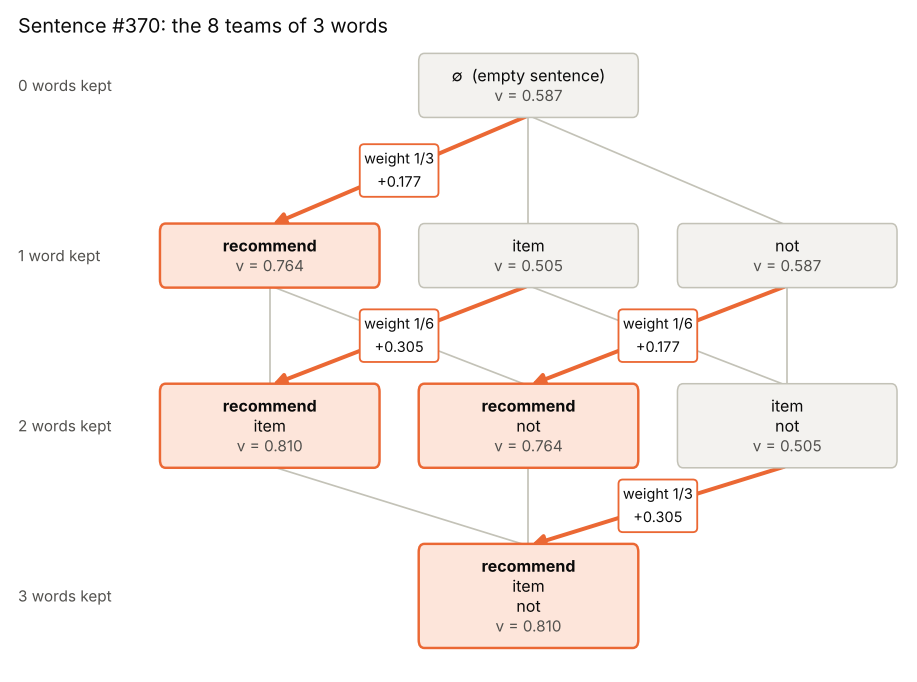

*The 8 teams that can be formed with 3 players ($2^3 = 8$). Orange arrows: the moments when *recommend* joins the team, with their weight and marginal contribution.*

- An **order** of the players is a **path** from the empty team (top) to the full team (bottom): with 3 players there are $3! = 3 \times 2 \times 1 = 6$ orders.
- The **orange arrows** are the 4 ways *recommend* can join the team: first, after *item*, after *not*, after both. Its marginal contribution changes: from +0.177 to +0.305.
- The **weight** of an arrow is the share of the 6 orders that pass through it: 2 orders start with *recommend* (weight 2/6 = 1/3), only 1 order goes *item* → *recommend* → *not* (weight 1/6), and so on.
- The **Shapley value** of *recommend* is the weighted average of its 4 marginal contributions:

$$\phi_{\text{recommend}} = \tfrac{1}{3}(+0.177) + \tfrac{1}{6}(+0.305) + \tfrac{1}{6}(+0.177) + \tfrac{1}{3}(+0.305) = +0.241$$

The same recipe gives -0.018 for *item* and exactly 0 for *not*: the three values add up to $0.810 - 0.587 = 0.223$, the distance between the full team and the empty team.

In general, with $n$ players, the Shapley value averages the marginal contribution over **all the orders**:

$$\phi_j \;=\; \frac{1}{n!}\sum_{\text{orders } R}\Bigl[\, v\bigl(P_j^R \cup \{j\}\bigr) - v\bigl(P_j^R\bigr) \Bigr]$$

where $P_j^R$ is the set of players that come **before** $j$ in the order $R$. With the 8 words of the sentence there are $2^8 = 256$ teams and $8! = 40{,}320$ orders: in Section 2.4 we average over 1,000 random orders.

💡 Look at the boxes of the figure that contain *not*: they always have the **same value** as the box without it ($v(\{\text{not}\}) = v(\varnothing)$, $v(\{\text{recommend}, \text{not}\}) = v(\{\text{recommend}\})$, ...). Adding *not* never changes the prediction: its Shapley value is exactly **0**.

## 2.3 Why is this split "fair"?

| Property | Meaning |
| :--- | :--- |
| **Efficiency** | $v(\varnothing) + \sum_j \phi_j = f(x)$: the contributions add up **exactly** to the prediction |
| **Symmetry** | two players that contribute the same to every team get the same value |
| **Dummy** | a player that never changes the prediction gets exactly $0$ (like *not* in the figure!) |
| **Additivity** | for a model made of a sum of models, the values add up |

Shapley proved that his value is the **only** split with all four properties.

## 2.4 🔧 SHAP by hand: sentence #370

Sentence #370 is a **negative** review, but the model says **positive** with high confidence; in Notebook 2, LIME showed that the model does not react to *not*. Let's split this prediction with Shapley's recipe, now with **all 8 words**. Two numbers of the figure in Section 2.2 come back here: $v(\varnothing) = 0.587$ (the empty sentence) and $v(\{\text{recommend}\}) = 0.764$.

In [ ]:
# ==========================================
# 4. THE VALUE OF A TEAM OF WORDS v(S)
# ==========================================

DOC = 370
sentence = X_test_txt[DOC]
print(sentence, "\n")

pieces = re.split(r"(\W+)", sentence)                  # words and separators (spaces, punctuation), in order
words = list(dict.fromkeys(p for p in pieces if re.fullmatch(r"\w+", p)))   # the players: the distinct words

def keep_only(team):
    # The sentence with only the words of the team (all the other words are removed)
    team = set(team)
    return "".join(p for p in pieces if not re.fullmatch(r"\w+", p) or p in team)

def v(S):
    # The value of team S = P(positive) of the sentence that contains only the words of S
    return text_model.predict_proba([keep_only(S)])[0, 1]

print(f"{len(words)} players (words): {words}")
print("The copy for the team {recommend, item, not}:", repr(" ".join(keep_only(["recommend", "item", "not"]).split())), "\n")
print(f"v(no words)         = {v([]):.3f}   <- base value: the empty sentence")
print(f"v(only 'recommend') = {v(['recommend']):.3f}")
print(f"v(only 'not')       = {v(['not']):.3f}   <- exactly the same as the empty sentence!")
print(f"v(all the words)    = {v(words):.3f}   <- the model's prediction f(x)")

In [ ]:
# ==========================================
# 5. TWO ORDERS, TWO DIFFERENT STORIES
# ==========================================

def contributions(order):
    # Marginal contribution of each word when the words join the team in this order:
    # P(positive) after the word joins - P(positive) before
    teams = [order[:k] for k in range(len(order) + 1)]                     # {}, {w1}, {w1, w2}, ...
    p = text_model.predict_proba([keep_only(team) for team in teams])[:, 1]
    return pd.Series(np.diff(p), index=order)[words]

orders = pd.DataFrame({"reading order": contributions(words),          # 'I' first, 'anyone' last
                       "reverse order": contributions(words[::-1])})   # 'anyone' first, 'I' last
print(orders.round(3), "\n")
print("Sum of the contributions:", orders.sum().round(3).tolist(), f"= f(x) - v(no words) = {v(words) - v([]):.3f}")

ax = orders.plot.barh(figsize=(8, 4.2), color=[BLUE, ORANGE], width=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("marginal contribution to P(positive)")
ax.set_title(f"Sentence #{DOC}: the same word, two different contributions", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

# QUESTION: BOTH ORDERS ADD UP TO THE SAME TOTAL, BUT 'item' GETS A DIFFERENT CREDIT IN THE TWO ORDERS, EVEN WITH A DIFFERENT SIGN. WHICH NUMBER IS THE "TRUE" ONE?

**Neither**: words interact (alone, *item* lowers P(positive); after *recommend* it raises it). Shapley's answer is to average over **all** orders. With 8 words there are 8! = 40,320 orders, so we average over 1,000 random ones.

In [ ]:
# ==========================================
# 6. AVERAGE OVER 1,000 RANDOM ORDERS = SHAPLEY VALUES
# ==========================================

rng = np.random.RandomState(0)
# 1,000 random orders of the 8 words; one row of contributions per order
all_orders = pd.DataFrame([contributions(list(rng.permutation(words))) for _ in range(1000)])
shap_by_hand = all_orders.mean()                 # Shapley value = average contribution over the orders
print(shap_by_hand.round(3).to_string(), "\n")

print(f"✅ Efficiency: v(no words) {v([]):.3f} + sum of the Shapley values {shap_by_hand.sum():+.3f} "
      f"= {v([]) + shap_by_hand.sum():.3f} = f(x) {v(words):.3f}")
print("✅ Dummy: words with a contribution of exactly 0 in EVERY order ->",
      [w for w in words if np.allclose(all_orders[w], 0)])

💡 The **dummy** property in action: *I*, *would*, *this*, *to* and *anyone* never change the prediction... and neither does **not**. For this model *"I would not recommend this item to anyone"* is the same as *"I would recommend this item to anyone"*. A Shapley value of **exactly 0** is a strong signal: whatever happens to these words, the model does not react. We find out why in Part 3.

In [ ]:
# ==========================================
# 7. THE SAME WITH THE shap LIBRARY
# ==========================================

masker = shap.maskers.Text(r"\W+")                    # the players are the words (split at spaces and punctuation)
text_explainer = shap.Explainer(text_model.predict_proba, masker, output_names=list(text_model.classes_))

sv_doc = text_explainer([sentence])[0, :, "positive"] # SHAP values of sentence #370 for the class 'positive'
shap.plots.text(sv_doc)                               # interactive: red words push toward positive, blue toward negative

def word_values(e):
    # The library gives one value per token (e.g. "recommend "): clean the tokens, add up repeated words
    values = pd.Series(e.values, index=[re.sub(r"\W+", "", token) for token in e.data])
    return values[values.index != ""].groupby(level=0).sum()

shap_doc = word_values(sv_doc)                        # word -> SHAP value, according to the library
# A quick check: our values (Section 2.4) next to the library's (+ 0.0 turns -0.000 into 0.000)
pd.DataFrame({"by hand (1,000 orders)": shap_by_hand, "shap library": shap_doc}).loc[words].round(3) + 0.0

✅ Same words, same signs, similar values: instead of random orders, the library uses a faster approximation (teams of neighbouring words, called *Owen values*). **From now on we use the library.**

### 💡 From the mechanism to the practice

| Because SHAP... | ...it can | ...but |
| :--- | :--- | :--- |
| removes words and measures the change in P(positive) | explain **any** text classifier (here a neural network) | many model calls for every explanation |
| averages over **all orders** | share the credit **fairly** when words interact | $2^n$ teams: with 30 words, ≈ 10⁹ teams → approximations are needed |
| satisfies **efficiency** | express each word's effect in **probability points** that add up exactly to $f(x)$ | — |
| gives exactly **0** to words the model ignores (dummy) | reveal what the model **cannot see** | — |
| starts from the **empty sentence** | answer *"why this sentence, compared with no information at all?"* | another reference would give other values |
| gives **consistent** local values | build a **global** view by aggregating many sentences (Part 3) | important ≠ causal |

# 🛒 Part 3 — SHAP on the sentiment model

## 3.1 Same model, same sentence: LIME vs SHAP

In [ ]:
# ==========================================
# 8. LIME vs SHAP FOR SENTENCE #370
# ==========================================

lime_explainer = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=42)
exp_lime = lime_explainer.explain_instance(sentence, text_model.predict_proba, num_features=len(words), num_samples=1000)
lime_weights = pd.Series(dict(exp_lime.as_list()))   # word -> LIME weight

both = pd.DataFrame({"LIME weight": lime_weights, "SHAP value": shap_doc}).loc[words]
ax = both.plot.barh(figsize=(8, 4.2), color=[BLUE, ORANGE], width=0.7)
ax.axvline(0, color=INK, lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("effect on P(positive)")
ax.set_title(f"Sentence #{DOC}: two explanations of the same model", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

💡 Same story: *recommend* pushes toward positive, and *not* does **nothing**. LIME gives the slopes of a local linear approximation (*not* gets a tiny, noisy weight); SHAP gives a fair split that **adds up** to the prediction, and *not* gets **exactly 0**.

## 3.2 ✅ Can we trust the explanation? Fidelity

An explanation is judged with a **different yardstick** than the model:

| | It compares... | It answers... |
| :--- | :--- | :--- |
| **Accuracy** | the model's predictions with the **true labels** | *is the model right?* |
| **Fidelity** | the explanation with the **model's predictions** | *does the explanation describe what the model really does?* |

⚠️ We never judge an explanation by its accuracy: a **faithful** explanation of a **wrong** prediction is exactly what we need to discover *why* the model is wrong.

**Fidelity of SHAP, step 1 - at the instance.** Thanks to *efficiency*, base value + sum of the SHAP values = $f(x)$, **exactly** (we checked it in Part 2). Lundberg & Lee call this property **local accuracy**: at the explained instance the fidelity is perfect by construction. LIME's linear model, instead, can miss $f(x)$.

**Fidelity of SHAP, step 2 - the ranking.** A sum can be exact even with wrong parts. The **deletion test** checks whether the explanation points at the features that **really** drive the decision: remove the $k$ features (here: words) that the explanation considers most important for the decision, and look at the prediction. If the explanation is faithful, the prediction must change **a lot**, much more than when we remove $k$ features chosen at random. We run the test with SHAP, with LIME and with a random choice, on the same model.

**Our test.** We take the first **50 sentences** of the test set and, for each one, **remove** the $k$ words ($k$ = 0, 1, 2, 3) that push most toward the class predicted by the model, according to SHAP, to LIME, or chosen at random. Then we look at the probability of the predicted class.

In [ ]:
# ==========================================
# 9. FIDELITY: THE DELETION TEST
# ==========================================

def remove(text, words_to_remove):
    # delete every occurrence of the given words (the other words, spaces and punctuation stay)
    to_remove = set(words_to_remove)
    return "".join(p for p in re.split(r"(\W+)", text) if p not in to_remove)

SAMPLE = X_test_txt[:50]                               # the first 50 test sentences
start = time.time()
sv_sample = text_explainer(SAMPLE)                     # SHAP values of the 50 sentences
print(f"SHAP for 50 sentences: {time.time() - start:.0f} seconds")

K = [0, 1, 2, 3]                                       # how many words we remove
rng = np.random.RandomState(0)
curves = {"SHAP": [], "LIME": [], "random": []}
for n, s in enumerate(SAMPLE):
    c = int(np.argmax(text_model.predict_proba([s])[0]))   # predicted class: 0 = negative, 1 = positive
    sign = 1 if c == 1 else -1                             # we want the words that push TOWARD the predicted class
    shap_rank = (sign * word_values(sv_sample[n, :, "positive"])).sort_values(ascending=False).index
    lime_w = pd.Series(dict(lime_explainer.explain_instance(s, text_model.predict_proba, num_features=50,
                                                            num_samples=500).as_list()))
    lime_rank = (sign * lime_w).sort_values(ascending=False).index
    distinct = list(dict.fromkeys(w for w in re.split(r"\W+", s) if w))      # all the words of the sentence
    prob = lambda text: text_model.predict_proba([text])[0, c]                # P(predicted class)
    curves["SHAP"].append([prob(remove(s, shap_rank[:k])) for k in K])
    curves["LIME"].append([prob(remove(s, lime_rank[:k])) for k in K])
    curves["random"].append(np.mean([[prob(remove(s, list(rng.permutation(distinct))[:k])) for k in K]
                                     for _ in range(10)], axis=0))           # average of 10 random choices

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, color in [("SHAP", ORANGE), ("LIME", BLUE), ("random", GRAY)]:
    mean_curve = np.mean(curves[name], axis=0)         # average over the 50 sentences
    ax.plot(K, mean_curve, marker="o", color=color, lw=2, label=f"{name}  ({mean_curve[-1]:.2f} after 3)")
ax.set_xticks(K)
ax.set_xlabel("number of words removed (k)")
ax.set_ylabel("average P(predicted class)")
ax.set_title("Deletion test: the faster the drop, the more faithful the explanation", loc="left")
ax.legend(frameon=False, loc="lower left", title="words chosen by", title_fontsize=9, fontsize=9)
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

💡 **How to read it**: all the curves start from the same point (nothing removed = the model's predictions). Removing the words indicated by **SHAP** or by **LIME** makes the model much less sure of its prediction; removing **random** words changes much less (often they are words the model ignores). Both explanations point at the words that **really** drive the model: they are faithful. It is the **model's behaviour**, not the true labels, that decides who passes the test: this is fidelity, not accuracy.

## 3.3 Global view: the words the model never uses

With SHAP, a word that the model ignores gets **exactly 0**. Let's put together the 50 explanations of Section 3.2 and look for the words that **never** change the prediction, in any sentence.

In [ ]:
# ==========================================
# 10. GLOBAL VIEW: THE WORDS THAT NEVER MATTER
# ==========================================

# One row per word occurrence in the 50 sentences: the word and its SHAP value
rows = []
for n in range(len(SAMPLE)):
    e = sv_sample[n, :, "positive"]
    for token, value in zip(e.data, e.values):
        word = re.sub(r"\W+", "", token).lower()
        if word:
            rows.append((word, value))
word_table = pd.DataFrame(rows, columns=["word", "shap"])
stats = word_table.groupby("word")["shap"].agg(count="count", largest=lambda s: s.abs().max())

# Words whose SHAP value is 0 in EVERY sentence where they appear
# (we treat values below 0.000001 as 0: tiny rounding errors of the computer)
never = stats[stats["largest"] < 1e-6].sort_values("count", ascending=False)
# words that can change the meaning of a review (negations, intensifiers, contrasts)
MEANING = ['not', 'no', 'never', 'nothing', 'none', 'but', 'too', 'very', 'more', 'most', 'much', 'less', 'least',
           'only', 'without', 'enough', 'well', 'few']
print(f"{len(never)} of the {len(stats)} different words of the 50 sentences NEVER change the prediction.")
print("👉 Among them, words that can change the meaning of a review:", [w for w in never.index if w in MEANING])

top = never["count"].head(20).iloc[::-1]                     # the 20 most frequent, for the chart
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, height=0.6, color=[ORANGE if w in MEANING else GRAY for w in top.index])
ax.set_xlabel("occurrences in the 50 sentences")
ax.set_title("Words with SHAP value = 0 every time they appear\n(orange: words that can change the meaning)", loc="left")
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

🎯 **One look is enough**: the words that **never** matter include, as expected, *the*, *a*, *and*..., but also words that can turn the meaning of a review around (in orange, and in the 👉 list above), such as **not** and **no**.

# QUESTION: WHY WOULD A MODEL BASED ON A NEURAL NETWORK, TRAINED ON MILLIONS OF SENTENCES, IGNORE "NOT"?

In [ ]:
# ==========================================
# 11. THE CULPRIT: WHAT DOES THE MODEL ACTUALLY READ?
# ==========================================

for s in [sentence, "Battery has no life.", "Never had anything to complain about here."]:
    print(f"original: {s}")
    print(f"cleaned : {clean(s)}\n")
print("Are they stop words?", {w: w in STOP_WORDS for w in ['not', 'no', 'never', 'nothing', 'without', 'very', 'but']})

# Negation words: they turn the meaning of a sentence around ("good" vs "not good")
NEGATIONS = ['not', 'no', 'never', 'nothing', 'none', 'nobody', 'neither', 'nor', 'cannot', 'without']
# True for the test sentences that contain at least one negation (words in lower case, punctuation dropped)
has_negation = np.array([any(w in NEGATIONS for w in re.findall(r"\w+", s.lower())) for s in X_test_txt])

ok = text_model.predict(X_test_txt) == np.array(y_test_txt)          # True where the model is right
print(f"\nAccuracy on the {has_negation.sum()} test sentences WITH a negation:     {ok[has_negation].mean():.1%}")
print(f"Accuracy on the {(~has_negation).sum()} test sentences WITHOUT a negation: {ok[~has_negation].mean():.1%}")

🐛 **Found it.** These words are all on scikit-learn's stop-word list, so the **cleaning step deletes them before the network can read them**: *"Battery has no life."* becomes *"battery life"*. The SHAP values of exactly 0 were telling the truth: these words never reach the model. On the sentences with a negation the model is right much less often.

Stop-word lists were made for search engines and word-counting models, where *not* is just a very frequent word. For sentiment it is one of the most important words, and an embedding model **can** understand it... if we let it read it.

## ✍️ Exercise — Fix the cleaning

1. **Step 1.** Put in `words_to_keep` the words that SHAP showed the model never sees (for example the negations). Re-run the two cells.
2. **Step 2.** An embedding model is made to read **whole sentences**. Try `CLEAN_TEXT = False` (no cleaning at all) and re-run the two cells.

⏱️ Each retraining takes less than a minute (all the training sentences go through the network again).

In [ ]:
# ==========================================
# 12. ✍️ EXERCISE: YOUR FIX
# ==========================================

words_to_keep = []          # 👉 Step 1: e.g. ['not', 'never'] = words that the cleaning must NOT remove
CLEAN_TEXT = True           # 👉 Step 2: False = no cleaning at all

new_stop_words = STOP_WORDS - set(words_to_keep)       # the stop-word list without the words to keep
fixed_text_model = train_sentiment_model(X_train_txt, y_train_txt, clean_text=CLEAN_TEXT, stop_words=new_stop_words)

In [ ]:
# ==========================================
# 13. BEFORE vs AFTER
# ==========================================

ok_new = fixed_text_model.predict(X_test_txt) == np.array(y_test_txt)   # True where the fixed model is right
results = pd.DataFrame({
    "Original model": [ok.mean(), ok[has_negation].mean(), ok[~has_negation].mean()],
    "Fixed model": [ok_new.mean(), ok_new[has_negation].mean(), ok_new[~has_negation].mean()]},
    index=["all test sentences", "sentences WITH a negation", "sentences WITHOUT a negation"])
dumbbell(results, "accuracy", "Accuracy on the test set, before and after the fix")
print(f"words_to_keep = {words_to_keep} | CLEAN_TEXT = {CLEAN_TEXT}")
if CLEAN_TEXT and not words_to_keep:
    print("ℹ️ Nothing changed: the fixed model is identical to the original. Use what SHAP showed you!")

# Sentence #370 explained again, with the fixed model
fixed_explainer = shap.Explainer(fixed_text_model.predict_proba, masker, output_names=list(fixed_text_model.classes_))
sv_fixed = fixed_explainer([sentence])[0, :, "positive"]
print(f"\nSentence #{DOC}: P(positive) = {fixed_text_model.predict_proba([sentence])[0, 1]:.3f} with the fixed model")
shap.plots.text(sv_fixed)

<details>
<summary>✅ <b>Solution</b> (click to open)</summary>

```python
words_to_keep = ['not', 'no', 'never', 'nothing', 'none', 'nobody', 'neither', 'nor', 'cannot', 'without']   # Step 1
CLEAN_TEXT = False                                                                                         # Step 2
```

- **Step 1** (keep the negations): the test accuracy goes from about 86% to about 92%, and on the sentences with a negation from about 63% to about 91%.
- **Step 2** (no cleaning): about 96% on all the test sentences, and about 96% also on the sentences with a negation (they were 63%!). An embedding model needs the **whole** sentence.
- In sentence #370, *not* now has the largest SHAP value, pushing toward **negative**: the sentence is classified correctly.

</details>

# QUESTION: THE TEST ACCURACY OF PART 1 LOOKED GOOD (86%). WHICH SHAP PROPERTY POINTED US TO THE BUG?

# ⚠️ Part 4 — The limits of SHAP

- **Cost**: exact Shapley values need all $2^n$ teams. With 30 words that is ≈ 10⁹ teams, so for text SHAP almost always uses approximations (random orders, or the library's teams of neighbouring words), and every explanation needs hundreds of calls to the neural network.
- **Reference point**: the base value is the **empty sentence**; a different reference (e.g. replacing words with `...` or with other words) would give different values.
- **Fidelity is exact only at $x$**: the values add up to $f(x)$ by construction, but how faithful the *ranking* is must be checked (deletion test).
- **Words, not meaning**: removing words creates unnatural sentences, and the interactions between words (irony, contrast) are spread over many small values.
- **Not causal**: SHAP explains the **model**, not the language. A large SHAP value means *"the model uses this word"*, not *"this word makes the review positive"*.

# 📌 Summary: LIME vs SHAP on the same text model

| | LIME (Notebook 2) | SHAP (this notebook) |
| :--- | :--- | :--- |
| Idea | local linear approximation | fair split of the prediction (Shapley value) |
| Contributions add up to the prediction | ❌ | ✅ (efficiency) |
| Words the model ignores | weight ≈ 0 (with some noise) | exactly 0 (dummy) |
| Fidelity | local $R^2$ | exact at $x$; both pass the deletion test |
| Global view | ❌ one sentence at a time | ✅ aggregate the local values |
| What it showed | *not* has no effect on sentence #370 and on other mistakes | *not*, *no* and the other stop words **never** reach the model |
| The fix | stop cleaning the text | → test accuracy from about 86% to about 96% |

### 🔑 The golden rules

> **Accuracy** tells you how often the **model** is right; **fidelity** tells you whether the **explanation** describes the model. A faithful explanation of a **wrong** model tells you **why** it is wrong, and that is the first step to make it right.

## 🎯 Final exercises

1. **Your own review.** Explain `"The battery does not last long."` with `text_explainer([...])` and `fixed_explainer([...])`, and draw both with `shap.plots.text`. Where does *not* go?
2. **Fewer orders.** In the SHAP-by-hand cell, average over 20 orders instead of 1,000. How much do the values change? Does efficiency still hold exactly? Why?
3. **The fixed model, globally.** Run the global view of Section 3.3 with `fixed_explainer` instead of `text_explainer`. Which words matter most now? Are there still words that never matter?
4. **The base value.** P(positive) of the empty sentence is not 0.5. Why? *(Hint: what does the model receive when all the words are removed?)*

---

### References

- Shapley, L. S. (1953). *A Value for n-Person Games*. Contributions to the Theory of Games II, 307-317.
- Lundberg, S. M., Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS 2017.
- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
- DeYoung, J. et al. (2020). *ERASER: A Benchmark to Evaluate Rationalized NLP Models*. ACL 2020 (deletion-based fidelity, "comprehensiveness").
- Molnar, C. *Interpretable Machine Learning* (free online book): <https://christophm.github.io/interpretable-ml-book/>
- Kotzias, D., Denil, M., de Freitas, N., Smyth, P. (2015). *From Group to Individual Labels Using Deep Features*. KDD 2015. Dataset: *Sentiment Labelled Sentences*, UCI Machine Learning Repository, <https://doi.org/10.24432/C57604> (CC BY 4.0).
- Xiao, S. et al. (2023). *C-Pack: Packaged Resources To Advance General Chinese Embedding* (the BGE embedding models). arXiv:2309.07597.
- Reimers, N., Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. EMNLP 2019.
- SHAP library: <https://github.com/shap/shap>